In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import os

# Tamaño de letra de todas las figuras
plt.rcParams.update({
    'font.size': 15,          # texto general
    'axes.titlesize': 16,     # título de cada panel
    'axes.labelsize': 16,     # etiquetas de los ejes
    'xtick.labelsize': 14,    # números del eje x
    'ytick.labelsize': 14,    # números del eje y
    'legend.fontsize': 12,    # leyendas
    'figure.titlesize': 18,   # título general (suptitle)
})

# Unidades adimensionales lambda = 1 y T = 1

def calcular_campos_dipolo(X, Z, t = 0.0, terminos=('1/r3', "1/r2", '1/r')):
    """
    Esta función calcula las componentes analíticas de los campos electromagnéticos (E, B) y el flujo de energía (vector de Poynting S) generados por un dipolo eléctrico oscilante ubicado en el origen. Evalúa las expresiones en un plano XZ utilizando unidades adimensionales (lambda = 1 y T = 1). Permite filtrar selectivamente qué términos analíticos evaluar ('1/r3', '1/r2', '1/r') para facilitar el análisis físico y transición entre regímenes espaciales.
    
    Argumentos:
        X (numpy.ndarray): Matriz de coordenadas espaciales en el eje x, expresadas en múltiplos de lambda
    
        Z (numpy.ndarray): Matriz de coordenadas espaciales en el eje z, expresadas en múltiplos de lambda
    
        t (float, opcional): Instante temporal en el que evalúan  los campos, expresado en fracciones o múltiplos de T.

        terminos (tuple de str): Tupla que especifica que dependencias radiales incluir en el cálculo. Por defecto incluye todos ('1/r3', '1/r2', '1/r') pero se puede personalizar a campo cercano ('1/r3'), a inducción ('1/r2') y raciación ('1/r').
    
    return:
        dict: Un diccionario que contiene los arreglos numéricos calculados para cada punto de la malla:
            - 'r': Distancia radial segura desde el origen (evita divisiones por cero).
            - 'E_r', 'E_theta': Componentes esféricas del campo eléctrico.
            - 'E_x', 'E_z': Componentes cartesianas del campo eléctrico proyectadas en el plano XZ.
            - 'B_phi': Componente azimutal del campo magnético.
            - 'S_r', 'S_theta': Componentes esféricas del vector de Poynting instantáneo.
            - 'S_x', 'S_z': Componentes cartesianas del vector de Poynting instantáneo.
            - 'S_prom_r', 'S_prom_x', 'S_prom_z': Componentes radiales y cartesianas del vector de Poynting promediado temporalmente en un ciclo completo.
    
    """
    k = 2 * np.pi
    omega = 2 * np.pi
    
    r = np.sqrt(X**2 + Z**2)
    
    # Para evitar la singularidad en el origen vamos a excluir los valores de r donde son 0
    
    r_safe = np.where(r==0, np.nan, r) # los asignamos como nan
    cos_t = Z / r_safe
    sin_t = X / r_safe
    delta = omega * t - k * r_safe
    kr = k * r_safe
    
    # Inicializar las componentes esfericas
    E_r = np.zeros_like(r_safe)
    E_theta = np.zeros_like(r_safe)
    B_phi = np.zeros_like(r_safe)
    
    if '1/r3' in terminos:
        E_r += 2 * cos_t * (np.cos(delta) / kr**3)
        E_theta += sin_t * (np.cos(delta) / kr**3)
        
    if '1/r2' in terminos:
        E_r -= 2 * cos_t * (np.sin(delta) / kr**2)
        E_theta -= sin_t * (np.sin(delta) / kr**2)
        B_phi -= sin_t * (np.sin(delta) / kr**2)
        
    if '1/r' in terminos:
        E_theta -= sin_t * (np.cos(delta) / kr)
        B_phi -= sin_t * (np.cos(delta) / kr)
        
    # Proyeccion al plano XZ para graficar vectores
    E_x = E_r * sin_t + E_theta * cos_t
    E_z = E_r * cos_t - E_theta * sin_t
    
    # Vector de Poynting instantaneo S = E x B
    S_r = E_theta * B_phi
    S_theta = - E_r * B_phi
    S_x = S_r * sin_t + S_theta * cos_t
    S_z = S_r * cos_t - S_theta * sin_t
    
    # Promedio temporal <S> en un ciclo
    S_prom_r = 0.5 * (sin_t**2) / (kr**2)
    S_prom_x = S_prom_r * sin_t
    S_prom_z = S_prom_r * cos_t
    
    return {
        'r': r_safe, 'E_r': E_r, 'E_theta': E_theta, 'E_x': E_x, 'E_z': E_z,'B_phi': B_phi, 'S_r': S_r, 'S_theta': S_theta,'S_x': S_x, 'S_z': S_z,'S_prom_r': S_prom_r,'S_prom_x': S_prom_x, 'S_prom_z': S_prom_z    
    }

In [10]:
TODOS = ('1/r3', '1/r2', '1/r')
K = 2 * np.pi

def _cerrar(fig, guardar):
    plt.tight_layout()
    if guardar:
        fig.savefig(guardar, dpi=150, bbox_inches='tight')
    plt.show()


# ---------------------------------------------------------------------------
# Aspecto 1: dependencia con r  (y pendientes 1/r^3, 1/r^2, 1/r)
# ---------------------------------------------------------------------------
def perfil_radial(theta_Er=45, theta_Eth=90, r_min=0.005, r_max=10, n=300,
                  t=0.0, guardar=None):
    r = np.logspace(np.log10(r_min), np.log10(r_max), n)
    ts = np.linspace(0, 1, 60, endpoint=False)
    paneles = [('E_r', theta_Er, r'$|E_r|$'),
               ('E_theta', theta_Eth, r'$|E_\theta|$'),
               ('B_phi', theta_Eth, r'$c\,|B_\phi|$')]
    estilos = [(('1/r3',), r'$1/r^3$', 'tab:blue'),
               (('1/r2',), r'$1/r^2$', 'tab:orange'),
               (('1/r',),  r'$1/r$',   'tab:green')]

    def amplitud(campo, X, Z, term):
        return np.max([np.abs(calcular_campos_dipolo(X, Z, t=ti, terminos=term)[campo])
                       for ti in ts], axis=0)

    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    print("Pendientes log-log de la amplitud TOTAL (esperado: -3 cerca, -1 lejos):")
    for ax, (campo, th, etiqueta) in zip(axes, paneles):
        X = r * np.sin(np.radians(th))
        Z = r * np.cos(np.radians(th))
        total_t = np.abs(calcular_campos_dipolo(X, Z, t=t)[campo])
        ax.loglog(r, total_t, 'k', lw=1, alpha=0.6, label=f'total en $t={t}T$')
        for term, lab, col in estilos:
            amp = amplitud(campo, X, Z, term)
            if amp.max() < 1e-12:      # este termino no existe en esta componente
                continue
            ax.loglog(r, amp, '--', color=col, lw=2, label=f'amplitud {lab}')
        env = amplitud(campo, X, Z, TODOS)
        ax.loglog(r, env, color='crimson', lw=1.5, label='amplitud total')
        ax.axvline(1 / K, color='gray', ls=':', label=r'$r=\lambda/2\pi$ ($kr=1$)')
        ax.set_xlabel(r'$r/\lambda$')
        ax.set_ylabel(etiqueta + ' (u.a.)')
        ax.set_title(f'{etiqueta} en $\\theta={th}^\\circ$')
        ax.legend(fontsize=8)
        ax.grid(True, which='both', alpha=0.25)
        cerca, lejos = r < 0.02, r > 3
        p_c = np.polyfit(np.log(r[cerca]), np.log(env[cerca]), 1)[0]
        p_l = np.polyfit(np.log(r[lejos]), np.log(env[lejos]), 1)[0]
        print(f"  {campo:8s} (theta={th}°): r<0.02λ -> {p_c:+.2f} ;  r>3λ -> {p_l:+.2f}")
    _cerrar(fig, guardar)


# ---------------------------------------------------------------------------
# Aspecto 2: comparar regimenes con ESCALA COMUN (log10 |campo|)
# ---------------------------------------------------------------------------
def explorar_regimen(r_max=(0.05, 1/(2*np.pi), 3.0), t=0.0, terminos=('1/r3', '1/r2', '1/r'),
                     titulo='', etiquetas=None, escala_comun=True, n=200, cmap='coolwarm',
                     guardar=None):
    """
    Visualiza E, B_phi y S(t) del dipolo oscilante en uno o varios regímenes espaciales,
    en una sola figura: cada FILA es un régimen (un r_max) y cada COLUMNA una magnitud.

    Condensa en una figura lo que antes hacían explorar_regimen (líneas de E, B_phi, S)
    y comparar_regimenes (mapas log10|campo| con la misma escala de color):
        - Columna 1: fondo log10|E| + líneas de campo de E.
        - Columna 2: fondo log10(c|B_phi|) + curvas B_phi = 0 (frentes donde B cambia de signo).
        - Columna 3: líneas de S(t) coloreadas por log10|S|.
    Con escala_comun=True todas las filas de una columna comparten la misma escala de color,
    de modo que la caída de los campos al pasar de r << lambda a r >> lambda se ve
    directamente comparando colores entre filas.

    Argumentos:
        r_max (float o tupla de float): semiancho de la ventana (en lambda) de cada régimen.
            Un solo número produce una sola fila.
        t (float): instante, en unidades de T.
        terminos (tuple de str): términos radiales a incluir ('1/r3', '1/r2', '1/r').
        titulo (str): texto al inicio del título general.
        etiquetas (list de str, opcional): nombre de cada fila. Por defecto r<<λ, r~λ/2π, r>>λ.
        escala_comun (bool): True -> una escala de color por columna compartida entre filas;
            False -> escala propia en cada panel.
        n (int): número de puntos por eje de la malla.
        cmap (str): mapa de color de matplotlib (por defecto azul->rojo, 'coolwarm').
        guardar (str, opcional): ruta para guardar la figura.
    """
    r_maxs = [float(v) for v in np.atleast_1d(r_max)]
    nf = len(r_maxs)
    if etiquetas is None:
        por_defecto = {3: [r'$r\ll\lambda$', r'$r\sim\lambda/2\pi$', r'$r\gg\lambda$'],
                       2: [r'$r\ll\lambda$', r'$r\gg\lambda$']}
        etiquetas = por_defecto.get(nf, [''] * nf)

    def log_abs(a):
        a = np.abs(a)
        return np.log10(np.where(a > 0, a, np.nan))

    # --- cálculo de cada régimen ---
    regs = []
    for rm in r_maxs:
        lin = np.linspace(-rm, rm, n)
        X, Z = np.meshgrid(lin, lin)
        d = calcular_campos_dipolo(X, Z, t=t, terminos=terminos)
        mascara = d['r'] < 0.06 * rm          # para el gráfico más bonito
        for clave in ['E_x', 'E_z', 'B_phi', 'S_x', 'S_z']:
            d[clave] = np.where(mascara, np.nan, d[clave])
        regs.append(dict(rm=rm, X=X, Z=Z, d=d,
                         logE=log_abs(np.hypot(d['E_x'], d['E_z'])),
                         logB=log_abs(d['B_phi']),
                         logS=log_abs(np.hypot(d['S_x'], d['S_z']))))

    def limites(claves_regs):
        v = np.concatenate([np.ravel(a) for a in claves_regs])
        v = v[np.isfinite(v)]
        return (np.percentile(v, 2), np.percentile(v, 98)) if v.size else None

    cols = [('logE', r'$\log_{10}|\mathbf{E}|$', 'Campo eléctrico $\\mathbf{E}$'),
            ('logB', r'$\log_{10}(c|B_\phi|)$', 'Campo magnético $B_\\phi$'),
            ('logS', r'$\log_{10}|\mathbf{S}|$', 'Flujo de energía instantáneo $\\mathbf{S}(t)$')]
    cero = {'logE': r'$\mathbf{E}$', 'logB': r'$B_\phi$', 'logS': r'$\mathbf{S}$'}
    lims_comunes = {c: limites([g[c] for g in regs]) for c, _, _ in cols}

    fig, axes = plt.subplots(nf, 3, figsize=(17, 4.9 * nf + 0.6), squeeze=False,
                             layout='constrained')
    mappables = {}

    for i, g in enumerate(regs):
        X, Z, d, rm = g['X'], g['Z'], g['d'], g['rm']
        for j, (clave, nom, tit) in enumerate(cols):
            ax = axes[i, j]
            lim = lims_comunes[clave] if escala_comun else limites([g[clave]])
            if lim is None:                       # la magnitud es idénticamente cero
                ax.text(0.5, 0.5, f'{cero[clave]} = 0\ncon estos términos',
                        ha='center', va='center', transform=ax.transAxes, fontsize=12)
                ax.set_facecolor('0.92')
            else:
                norm = Normalize(*lim)
                if clave == 'logE':
                    m = ax.pcolormesh(X, Z, g['logE'], cmap=cmap, norm=norm, shading='auto')
                    ax.streamplot(X, Z, d['E_x'], d['E_z'], color='k',
                                  linewidth=0.6, density=1.2, arrowsize=0.7)
                elif clave == 'logB':
                    m = ax.pcolormesh(X, Z, g['logB'], cmap=cmap, norm=norm, shading='auto')
                    ax.contour(X, Z, d['B_phi'], levels=[0], colors='k',
                               linewidths=0.8, linestyles='dotted')
                else:
                    sp = ax.streamplot(X, Z, d['S_x'], d['S_z'], color=g['logS'],
                                       cmap=cmap, norm=norm, linewidth=1.1, density=1.2)
                    m = sp.lines
                    ax.set_facecolor('0.2')
                mappables[(i, j)] = m
                if not escala_comun:
                    fig.colorbar(m, ax=ax, label=nom, shrink=0.9)

            ax.set_xlim(-rm, rm)
            ax.set_ylim(-rm, rm)
            ax.set_aspect('equal')
            ax.set_xlabel(r'$x/\lambda$')
            ax.set_ylabel(r'$z/\lambda$')
            if i == 0:
                ax.set_title(tit, fontsize=12)
        axes[i, 0].set_ylabel(f'{etiquetas[i]}   ($r_{{max}}={rm:.3g}\\lambda$)\n' + r'$z/\lambda$')

    if escala_comun:                              # una barra por columna, común a todas las filas
        for j, (clave, nom, _) in enumerate(cols):
            m = next((mappables[(i, j)] for i in range(nf) if (i, j) in mappables), None)
            if m is not None:
                fig.colorbar(m, ax=axes[:, j], label=nom, shrink=0.9 / max(1, nf ** 0.3))

    escala = 'escala de color común por columna' if escala_comun else 'escala propia por panel'
    fig.suptitle(f'{titulo}  ($t={t}T$, términos: {", ".join(terminos)}; {escala})', fontsize=13)
    if guardar:
        fig.savefig(guardar, dpi=150, bbox_inches='tight')
    plt.show()


# ---------------------------------------------------------------------------
# Aspecto 3: orientacion relativa de E, B y propagacion (region de radiacion)
# ---------------------------------------------------------------------------
def orientacion_radiacion(centro=(2.1, 2.1), semiancho=0.6, t=0.0,
                          n_flechas=13, guardar=None):
    cx, cz = centro
    lx = np.linspace(cx - semiancho, cx + semiancho, 200)
    lz = np.linspace(cz - semiancho, cz + semiancho, 200)
    X, Z = np.meshgrid(lx, lz)
    d = calcular_campos_dipolo(X, Z, t=t)
    vmax = np.nanmax(np.abs(d['B_phi']))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6),
                                   gridspec_kw={'width_ratios': [1.15, 1]})
    im = ax1.pcolormesh(X, Z, d['B_phi'], cmap='RdBu_r', vmin=-vmax, vmax=vmax,
                        shading='auto')
    plt.colorbar(im, ax=ax1, label=r'$B_\phi$  (>0: entra a la pagina, $+\hat y$)')
    idx = np.linspace(0, 199, n_flechas).astype(int)
    sub = np.ix_(idx, idx)
    # flechas con longitud proporcional a la magnitud (relativa al maximo de la ventana)
    Emax = np.nanmax(np.hypot(d['E_x'], d['E_z']))
    Smax = np.nanmax(np.hypot(d['S_x'], d['S_z']))
    ax1.quiver(X[sub], Z[sub], (d['E_x'] / Emax)[sub], (d['E_z'] / Emax)[sub],
               color='navy', pivot='mid', scale=11, width=0.005, label=r'$\mathbf{E}$')
    ax1.quiver(X[sub], Z[sub], (d['S_x'] / Smax)[sub], (d['S_z'] / Smax)[sub],
               color='lime', pivot='tail', scale=11, width=0.005, label=r'$\mathbf{S}$')
    ax1.set_aspect('equal')
    ax1.set_xlabel(r'$x/\lambda$')
    ax1.set_ylabel(r'$z/\lambda$')
    ax1.set_title(f'Region de radiacion (r~{np.hypot(cx, cz):.1f}$\\lambda$), $t={t}T$:\n'
                  r'E (azul), S (verde, direccion de propagacion), $B_\phi$ (color)')
    ax1.legend(loc='upper right')

    # a lo largo de un rayo: E_theta vs c B_phi, y E_r
    th = np.arctan2(cx, cz)
    r = np.linspace(np.hypot(cx, cz) - 1.5, np.hypot(cx, cz) + 1.5, 400)
    dr = calcular_campos_dipolo(r * np.sin(th), r * np.cos(th), t=t)
    ax2.plot(r, dr['E_theta'], lw=2, label=r'$E_\theta$')
    ax2.plot(r, dr['B_phi'], '--', lw=2, label=r'$cB_\phi$')
    ax2.plot(r, dr['E_r'], lw=1.2, color='gray', label=r'$E_r$ (longitudinal)')
    ax2.set_xlabel(r'$r/\lambda$')
    ax2.set_ylabel('u.a.')
    ax2.set_title(r'A lo largo de un rayo: $E_\theta$ y $cB_\phi$ en fase e iguales')
    ax2.legend()
    ax2.grid(alpha=0.3)
    _cerrar(fig, guardar)

    # verificaciones numericas (en los puntos de la ventana)
    ok = np.abs(dr['B_phi']) > 0.2 * np.abs(dr['B_phi']).max()
    print("Verificaciones en la region de radiacion:")
    print(f"  E_theta / (c B_phi)   = {np.mean(dr['E_theta'][ok] / dr['B_phi'][ok]):.4f}  (esperado -> 1)")
    print(f"  max|E_r| / max|E_theta| = {np.abs(dr['E_r']).max() / np.abs(dr['E_theta']).max():.4f}  (esperado ~ 2cos(theta)/kr, pequeno)")
    ang = np.degrees(np.arctan2(d['S_theta'], d['S_r']))
    w = np.hypot(d['S_r'], d['S_theta'])
    ok2 = np.isfinite(ang)
    print(f"  angulo entre S y r_hat (ponderado por |S|): {np.average(np.abs(ang[ok2]), weights=w[ok2]):.2f}°  (esperado ~ 0°)")


# ---------------------------------------------------------------------------
# Aspecto 4: Poynting promediado (ANALITICO) + comparacion cerca/lejos (4.3)
# ---------------------------------------------------------------------------
def poynting_promedio(r_max=1.5, n=120, puntos=((0.02, 60), (3.0, 60)),
                      t_inst=(0.0, 0.125), guardar=None):
    """<S> se toma de la expresion analitica (S_prom_*), no de una integral numerica.
    S(t) instantaneo se evalua en los instantes t_inst para comparar."""
    lin = np.linspace(-r_max, r_max, n)
    X, Z = np.meshgrid(lin, lin)
    d = calcular_campos_dipolo(X, Z)
    r = d['r']
    mag = np.hypot(d['S_prom_x'], d['S_prom_z'])
    mascara = (r < 0.08 * r_max) | ~np.isfinite(mag)
    Sx = np.ma.masked_where(mascara, d['S_prom_x'])
    Sz = np.ma.masked_where(mascara, d['S_prom_z'])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    sp = ax1.streamplot(X, Z, Sx, Sz, color=np.log10(np.where(mascara, np.nan, mag)),
                        cmap='inferno', density=1.4)
    plt.colorbar(sp.lines, ax=ax1, label=r'$\log_{10}|\langle\mathbf{S}\rangle|$')
    ax1.set_aspect('equal')
    ax1.set_title(r'$\langle\mathbf{S}\rangle$: $S_0\,\sin^2\theta/(2k^2 r^2)\,\hat r$')
    ax1.set_xlabel(r'$x/\lambda$')
    ax1.set_ylabel(r'$z/\lambda$')

    # r^2 <S_r> vs r y r^2 |S(t)| en instantes dados (theta = 90 grados)
    rr = np.logspace(-2, np.log10(5), 300)
    d90 = calcular_campos_dipolo(rr, np.zeros_like(rr))
    ax2.loglog(rr, rr**2 * d90['S_prom_r'], lw=2.5, label=r'$r^2\langle S_r\rangle$ (flujo neto)')
    for ti, est in zip(t_inst, ('--', ':', '-.', '-')):
        di = calcular_campos_dipolo(rr, np.zeros_like(rr), t=ti)
        ax2.loglog(rr, rr**2 * np.hypot(di['S_r'], di['S_theta']), est, lw=1.8,
                   label=rf'$r^2|\mathbf{{S}}(t)|$, $t={ti}T$')
    ax2.axvline(1 / K, color='gray', ls=':')
    ax2.set_xlabel(r'$r/\lambda$')
    ax2.set_ylabel('u.a.')
    ax2.set_title(r'$\theta=90^\circ$: energia neta vs energia instantanea')
    ax2.legend(fontsize=8)
    ax2.grid(True, which='both', alpha=0.25)
    _cerrar(fig, guardar)

    print("Comparacion de puntos (unidades de S0):")
    for (rp, thp) in puntos:
        th = np.radians(thp)
        Xp, Zp = np.array([rp * np.sin(th)]), np.array([rp * np.cos(th)])
        dp = calcular_campos_dipolo(Xp, Zp)
        print(f"  r={rp}λ (kr={K*rp:.2f}), θ={thp}°:")
        print(f"     <S_r> analitico = {dp['S_prom_r'][0]:.4e}   (dirección: radial, <S_θ>=0)")
        for ti in t_inst:
            di = calcular_campos_dipolo(Xp, Zp, t=ti)
            S_i = np.hypot(di['S_r'][0], di['S_theta'][0])
            print(f"     |S(t={ti}T)| = {S_i:.4e}   | <S_r>/|S(t)| = {dp['S_prom_r'][0]/S_i:.4f}")


# ---------------------------------------------------------------------------
# Aspecto 5: patron angular dP/dOmega  (seccion 4.2)  -- ANALITICO
# ---------------------------------------------------------------------------
def patron_angular(r_lejano=10.0, angulos=(0, 30, 45, 60, 90), guardar=None):
    """dP/dOmega = r^2 <S_r>, usando <S_r> analitico (S_prom_r) del codigo."""
    th = np.radians(np.linspace(0, 180, 361))
    d = calcular_campos_dipolo(r_lejano * np.sin(th), r_lejano * np.cos(th))
    dPdO = r_lejano**2 * d['S_prom_r']
    dPdO_norm = dPdO / np.nanmax(dPdO)

    fig = plt.figure(figsize=(13, 5.5))
    ax1 = fig.add_subplot(1, 2, 1, projection='polar')
    ang_full = np.concatenate([th, 2 * np.pi - th[::-1]])
    ax1.plot(ang_full, np.concatenate([dPdO_norm, dPdO_norm[::-1]]), lw=2)
    ax1.set_theta_zero_location('N')
    ax1.set_theta_direction(-1)
    ax1.set_title(r'$dP/d\Omega\propto\sin^2\theta$ (eje del dipolo: vertical)')

    ax2 = fig.add_subplot(1, 2, 2)
    ax2.plot(np.degrees(th), dPdO_norm, lw=2)
    ax2.set_xlabel(r'$\theta$ (grados)')
    ax2.set_ylabel(r'$(dP/d\Omega)/(dP/d\Omega)_{max}$')
    ax2.grid(alpha=0.3)
    _cerrar(fig, guardar)

    print("Valores relativos de dP/dΩ (normalizados a θ=90°):")
    for a in angulos:
        i = np.argmin(np.abs(np.degrees(th) - a))
        print(f"  θ={a:3d}°: dP/dΩ relativo = {dPdO_norm[i]:.4f}  (sin²θ = {np.sin(np.radians(a))**2:.4f})")


# ---------------------------------------------------------------------------
# Aspecto 1 (extra): superficie 3D del campo en funcion de r y t
# ---------------------------------------------------------------------------
def perfil_radial_3d(theta=90, campo='E_theta', r_min=0.05, r_max=3.0,
                     nr=300, nt=120, elev=28, azim=-60, colorear=True,
                     guardar=None):
    """Superficie 3D de campo(r, t). El campo se recorta a un valor maximo
    (percentil 90 de |campo|) para que la region lejana no quede plana.
    colorear=False dibuja la superficie en un solo color."""
    nombres = {'E_theta': r'$E_\theta$', 'E_r': r'$E_r$', 'B_phi': r'$cB_\phi$'}
    r = np.linspace(r_min, r_max, nr)
    t = np.linspace(0, 1, nt)
    R, T = np.meshgrid(r, t)
    X = R * np.sin(np.radians(theta))
    Z = R * np.cos(np.radians(theta))
    F = calcular_campos_dipolo(X, Z, t=T)[campo]

    zl = np.nanpercentile(np.abs(F), 90)        # tope visual
    Fc = np.clip(F, -zl, zl)

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(1, 1, 1, projection='3d')
    if colorear:
        ax.plot_surface(R, T, Fc, cmap='coolwarm', vmin=-zl, vmax=zl,
                        linewidth=0, antialiased=True, rcount=100, ccount=150)
    else:
        ax.plot_surface(R, T, Fc, color='steelblue', alpha=0.9,
                        linewidth=0, antialiased=True, rcount=100, ccount=150)
    ax.set_xlabel(r'$r/\lambda$')
    ax.set_ylabel(r'$t/T$')
    ax.set_zlabel(nombres[campo] + ' (recortado)')
    ax.set_zlim(-zl, zl)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(f'{nombres[campo]}$(r,t)$ en $\\theta={theta}^\\circ$')
    _cerrar(fig, guardar)

In [12]:
os.makedirs('figuras', exist_ok=True)
REG = (0.05, 1/(2*np.pi), 3.0)      

Pendientes log-log de la amplitud TOTAL (esperado: -3 cerca, -1 lejos):
  E_r      (theta=45°): r<0.02λ -> -3.00 ;  r>3λ -> -2.00
  E_theta  (theta=90°): r<0.02λ -> -3.00 ;  r>3λ -> -1.00
  B_phi    (theta=90°): r<0.02λ -> -2.00 ;  r>3λ -> -1.00


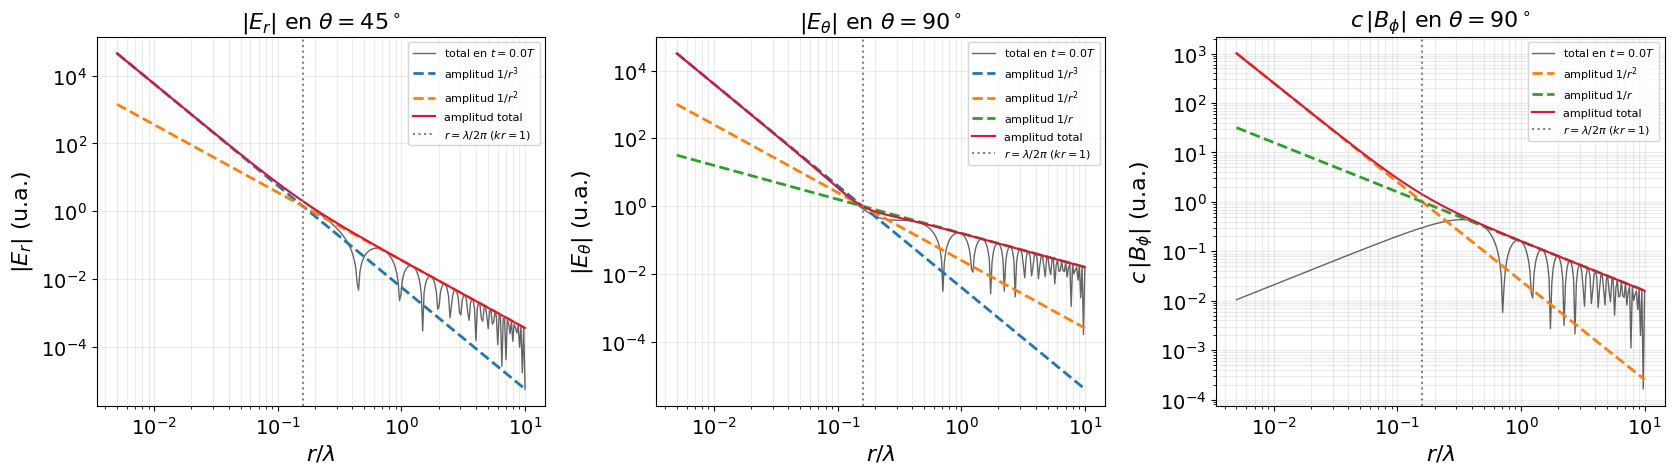

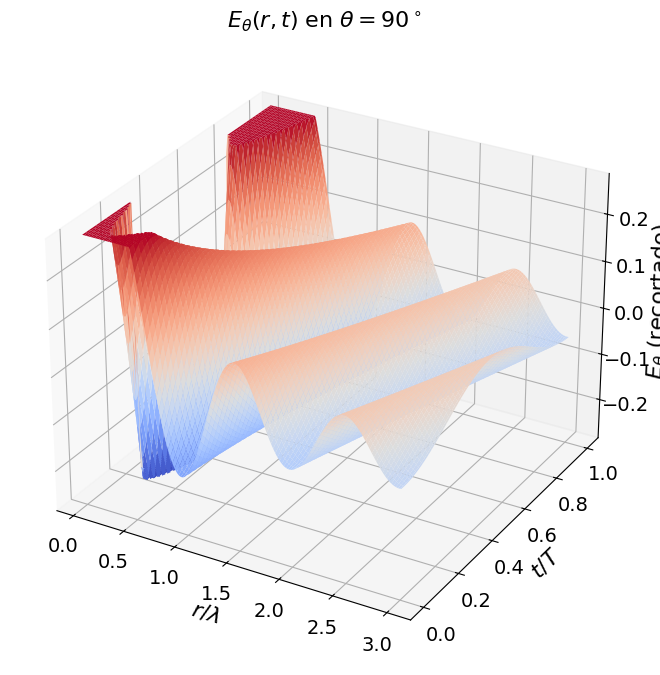

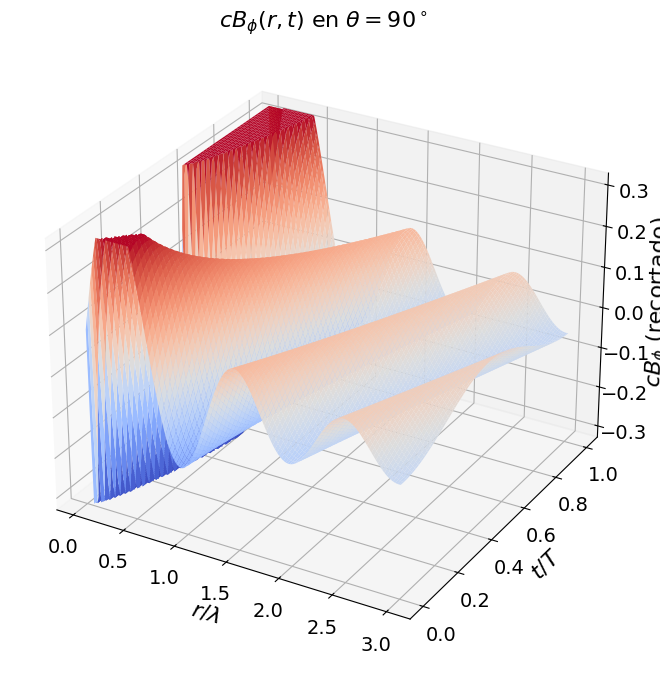

In [13]:
# Aspecto 1: dependencia con r (pendientes -3, -2, -1)
perfil_radial(guardar='figuras/fig1_perfil_radial.png')
# superficies 3D campo(r, t)
perfil_radial_3d(guardar='figuras/fig1b_superficie_3d_Etheta.png')
perfil_radial_3d(campo='B_phi', guardar='figuras/fig1c_superficie_3d_Bphi.png')

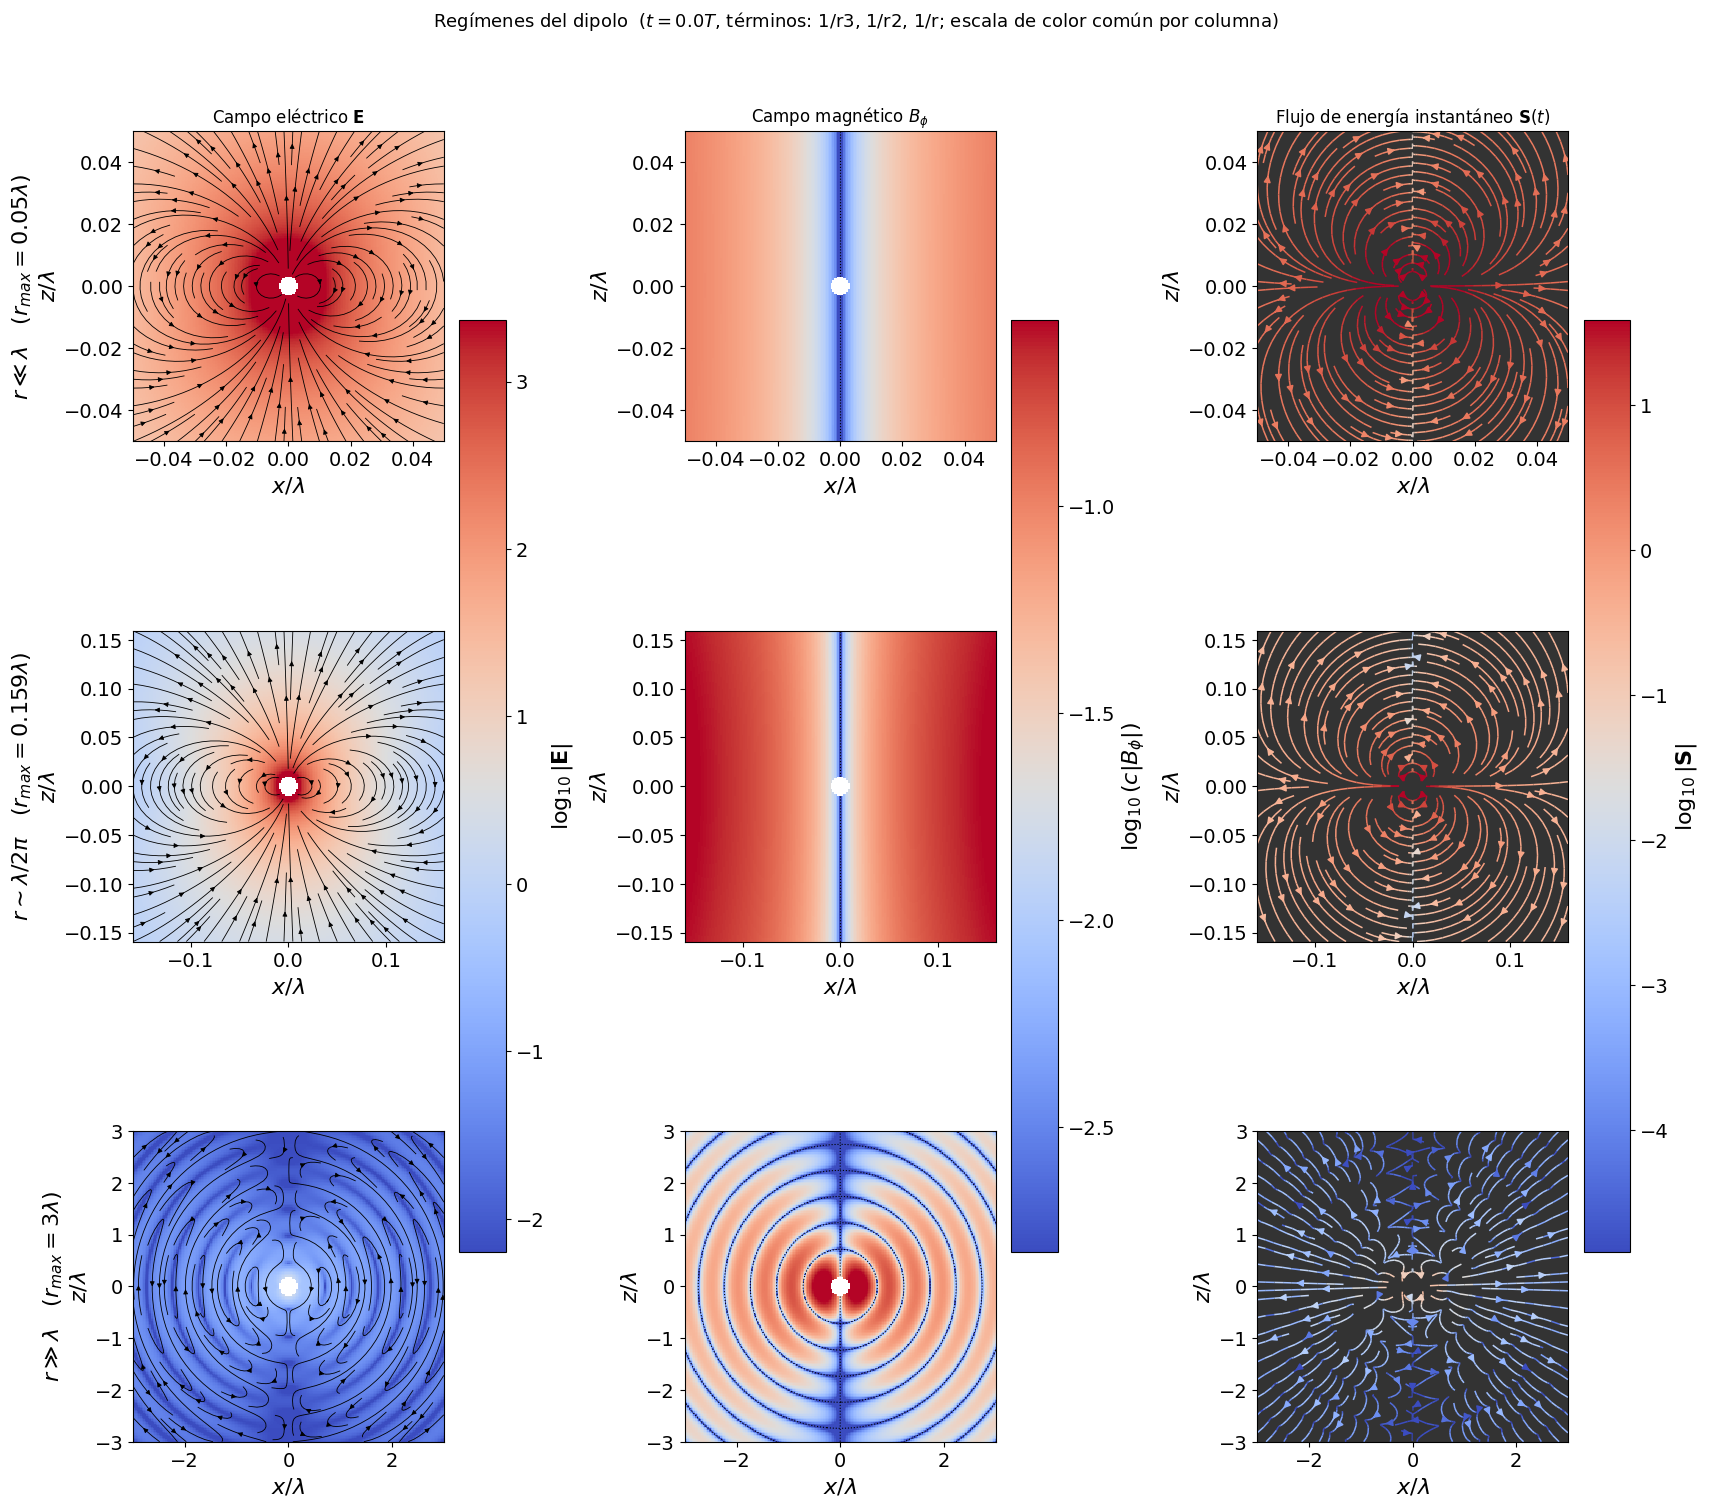

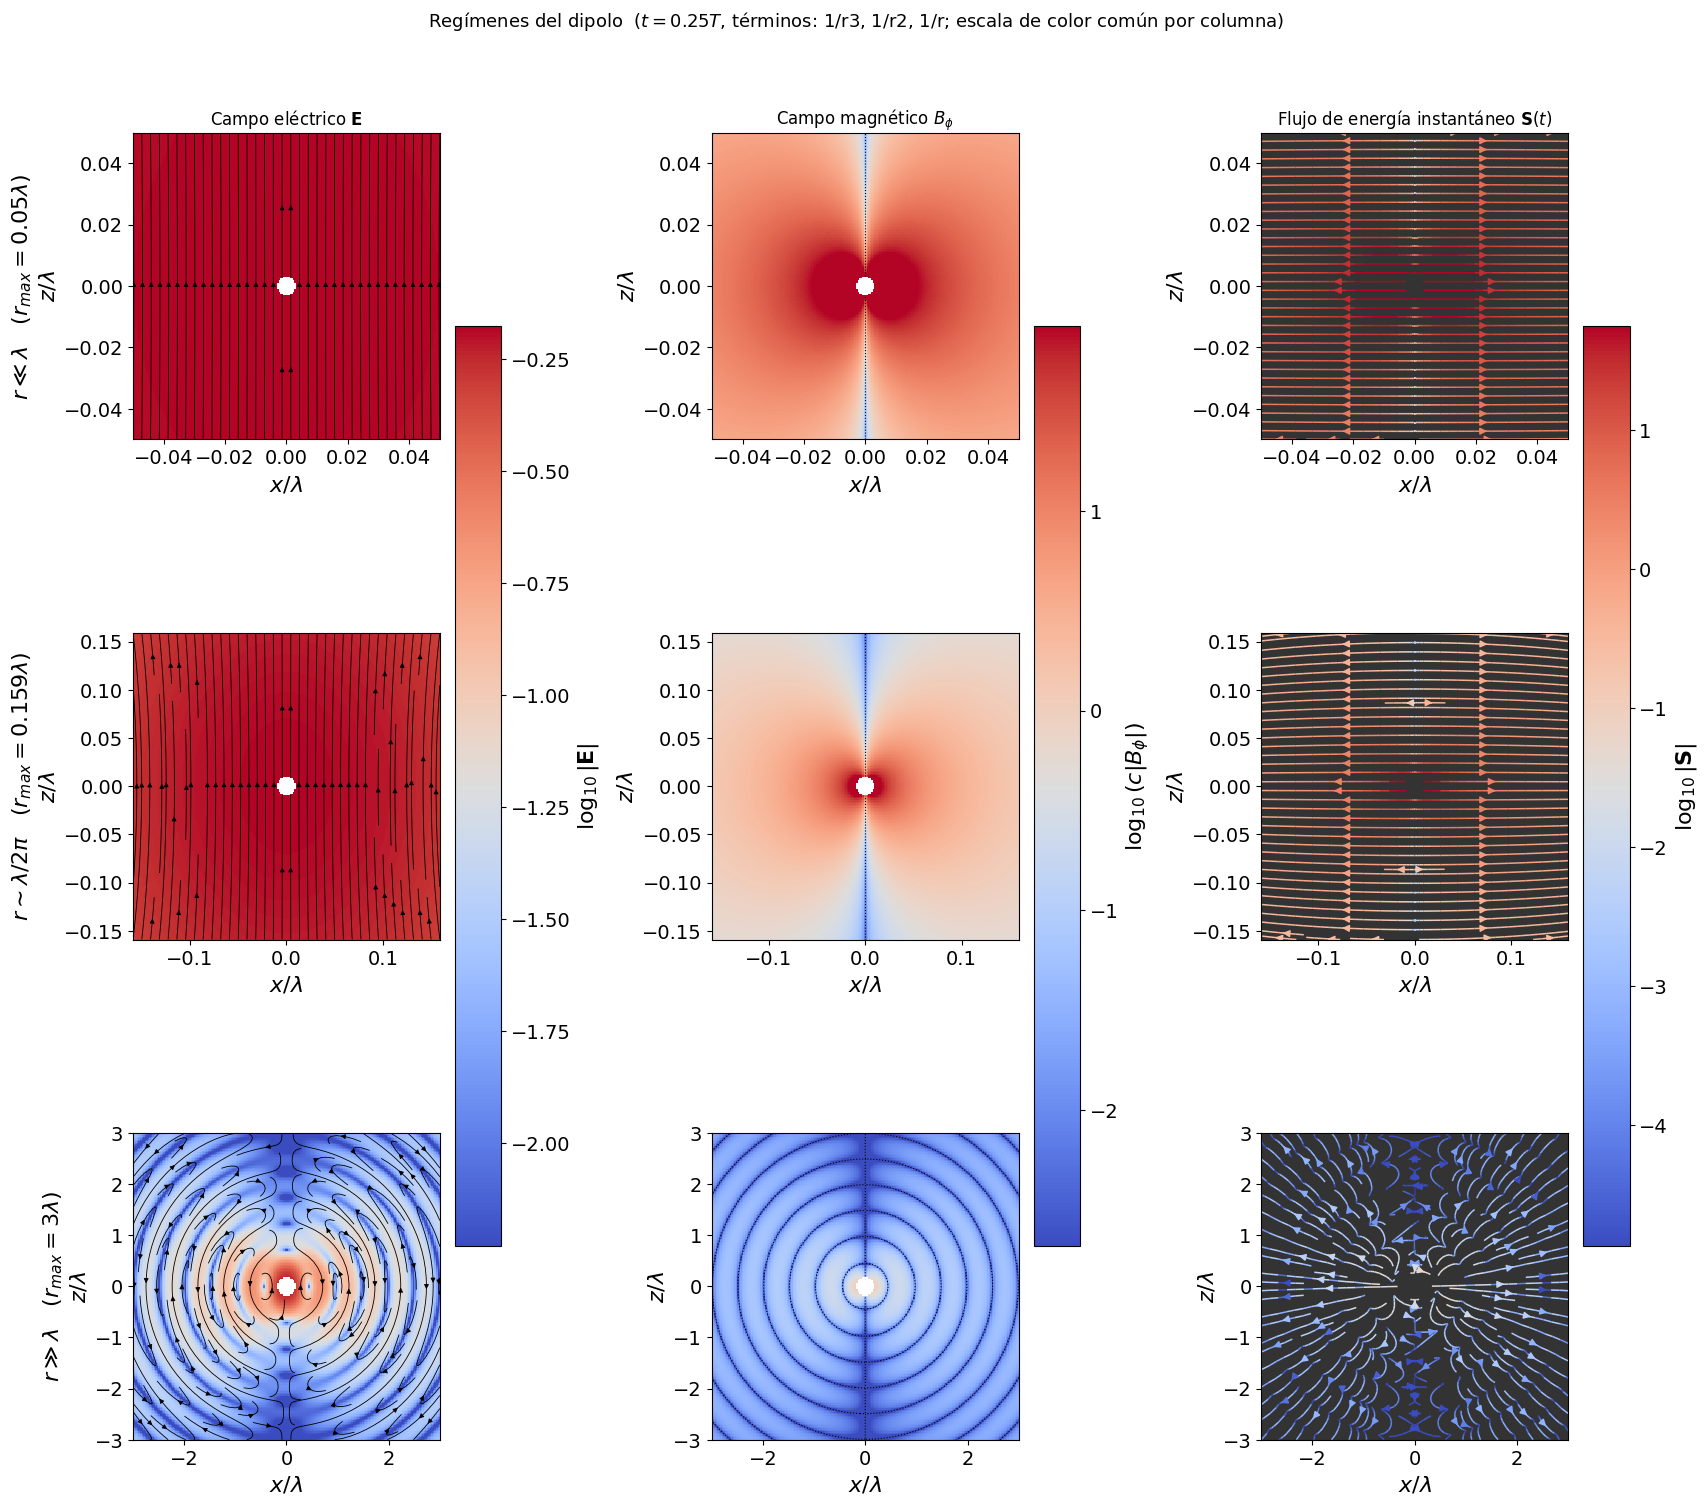

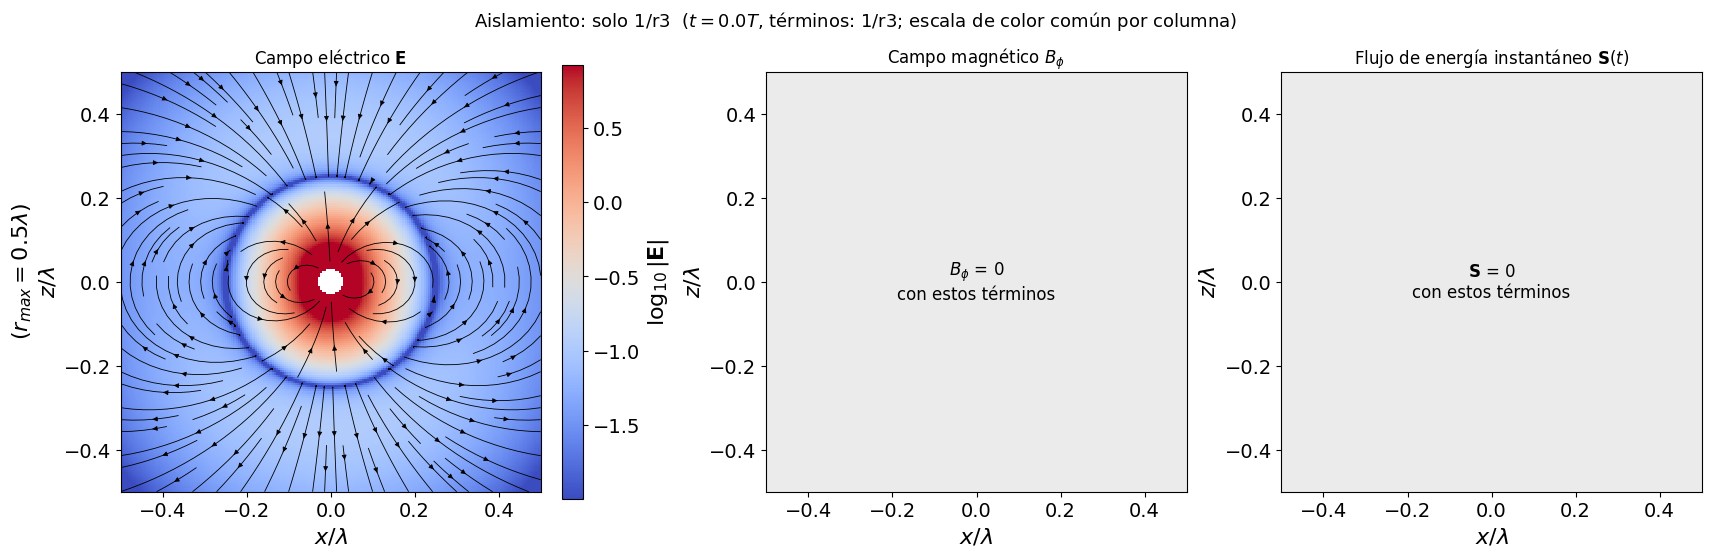

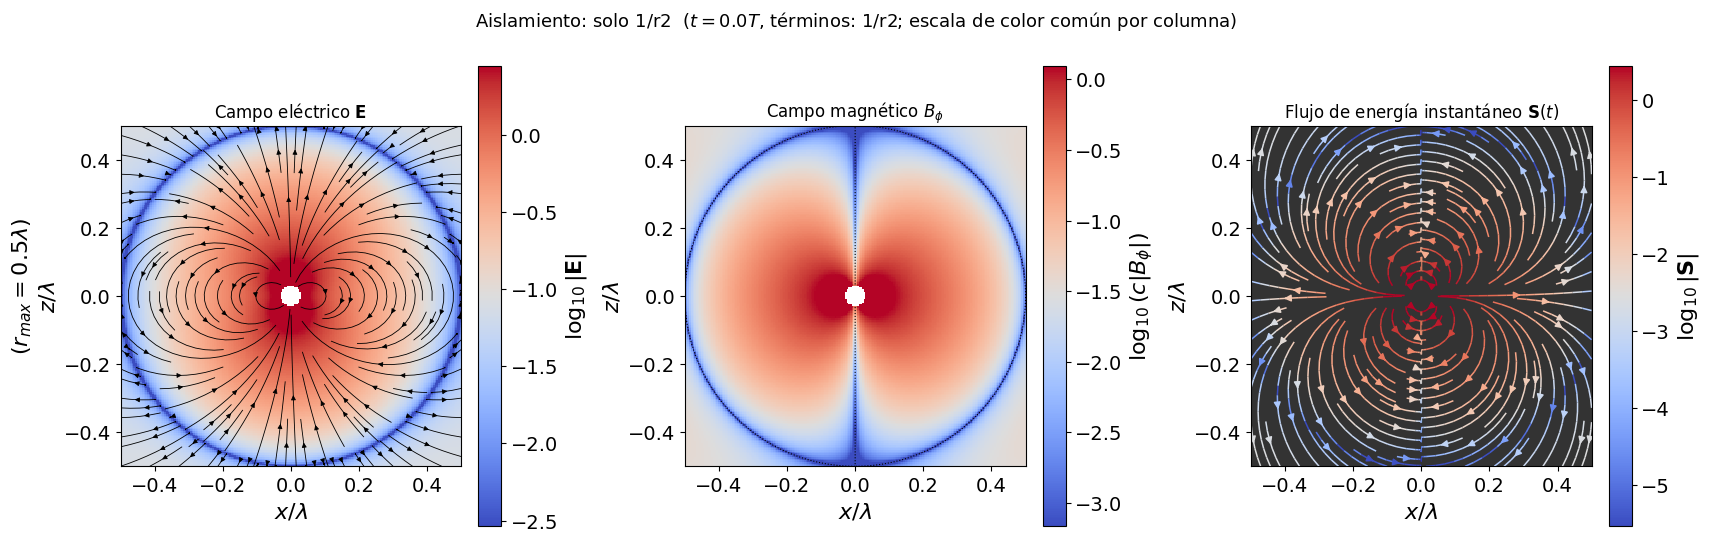

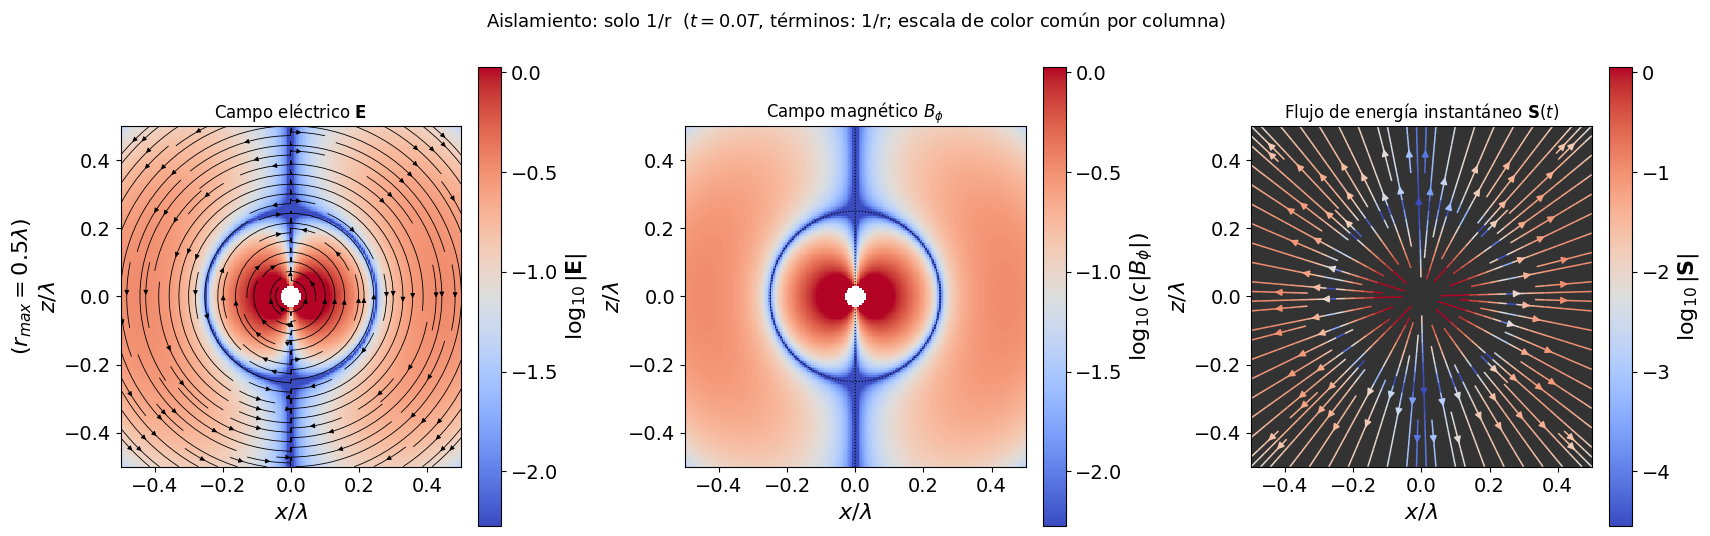

In [15]:
# Aspecto 2: los tres regímenes, escala común
explorar_regimen(r_max=REG, t=0.0, titulo="Regímenes del dipolo",
                 guardar='figuras/fig2a_regimenes_t0.png')
explorar_regimen(r_max=REG, t=0.25, titulo="Regímenes del dipolo",
                 guardar='figuras/fig2b_regimenes_t025.png')
#aislamiento de términos, todos en la misma ventana
for term, nombre in [(('1/r3',), '1r3'), (('1/r2',), '1r2'), (('1/r',), '1r')]:
    explorar_regimen(r_max=0.5, terminos=term, titulo=f"Aislamiento: solo {term[0]}",
                     guardar=f'figuras/fig3_aislado_{nombre}.png')

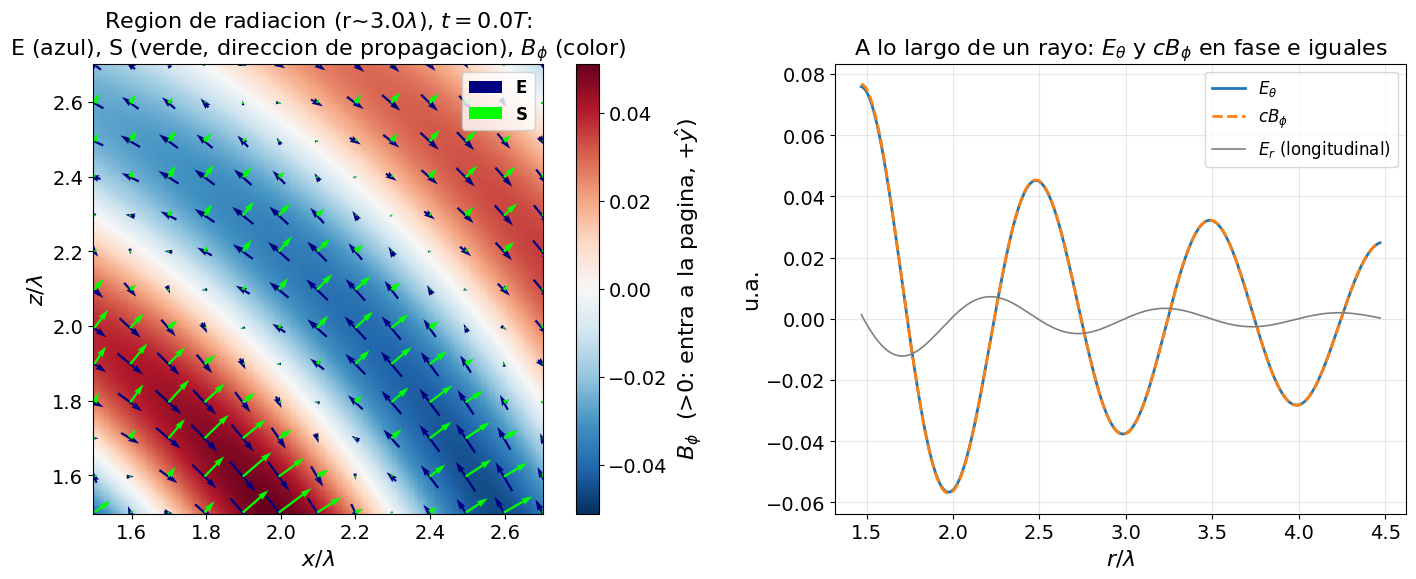

Verificaciones en la region de radiacion:
  E_theta / (c B_phi)   = 0.9958  (esperado -> 1)
  max|E_r| / max|E_theta| = 0.1602  (esperado ~ 2cos(theta)/kr, pequeno)
  angulo entre S y r_hat (ponderado por |S|): 3.93°  (esperado ~ 0°)


In [16]:
# Fig. 4 — Aspecto 3: orientación de E, B y S en la zona de radiación
orientacion_radiacion(guardar='figuras/fig4_orientacion.png')

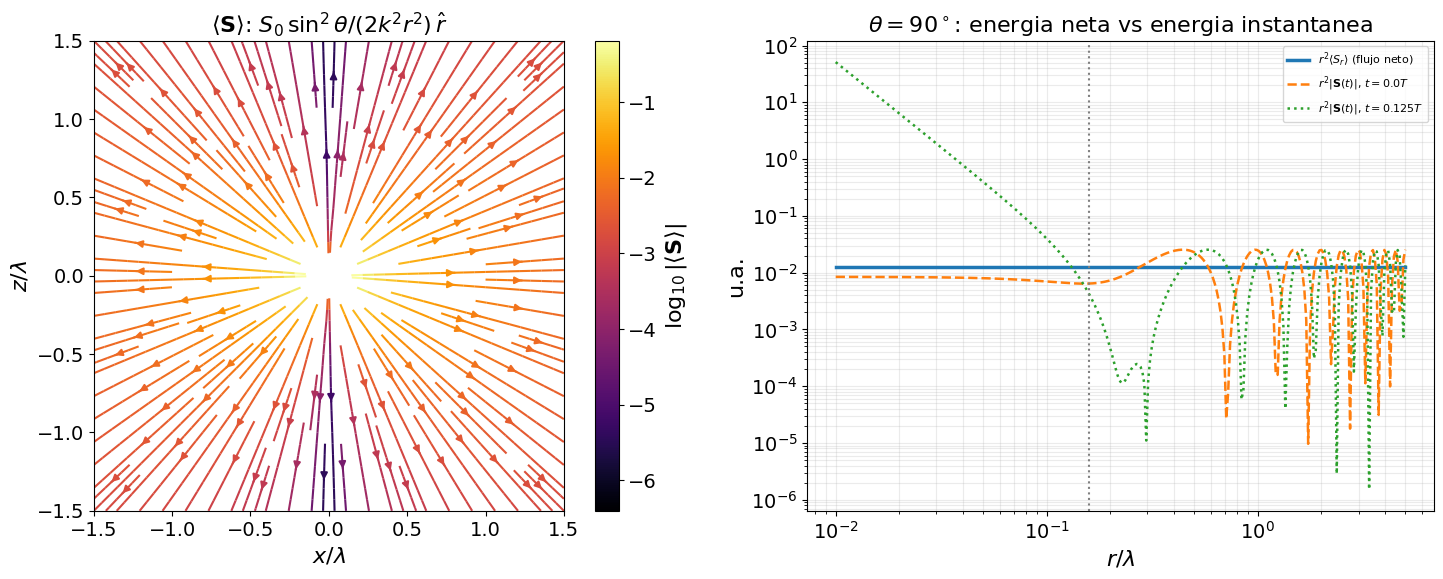

Comparacion de puntos (unidades de S0):
  r=0.02λ (kr=0.13), θ=60°:
     <S_r> analitico = 2.3747e+01   (dirección: radial, <S_θ>=0)
     |S(t=0.0T)| = 2.4173e+01   | <S_r>/|S(t)| = 0.9824
     |S(t=0.125T)| = 1.8430e+04   | <S_r>/|S(t)| = 0.0013
  r=3.0λ (kr=18.85), θ=60°:
     <S_r> analitico = 1.0554e-03   (dirección: radial, <S_θ>=0)
     |S(t=0.0T)| = 2.1049e-03   | <S_r>/|S(t)| = 0.5014
     |S(t=0.125T)| = 1.1690e-03   | <S_r>/|S(t)| = 0.9028


In [17]:
# Fig. 5 — Aspecto 4 / 4.3: Poynting promedio vs instantáneo, punto cercano y lejano
poynting_promedio(puntos=((0.02, 60), (3.0, 60)), guardar='figuras/fig5_poynting.png')

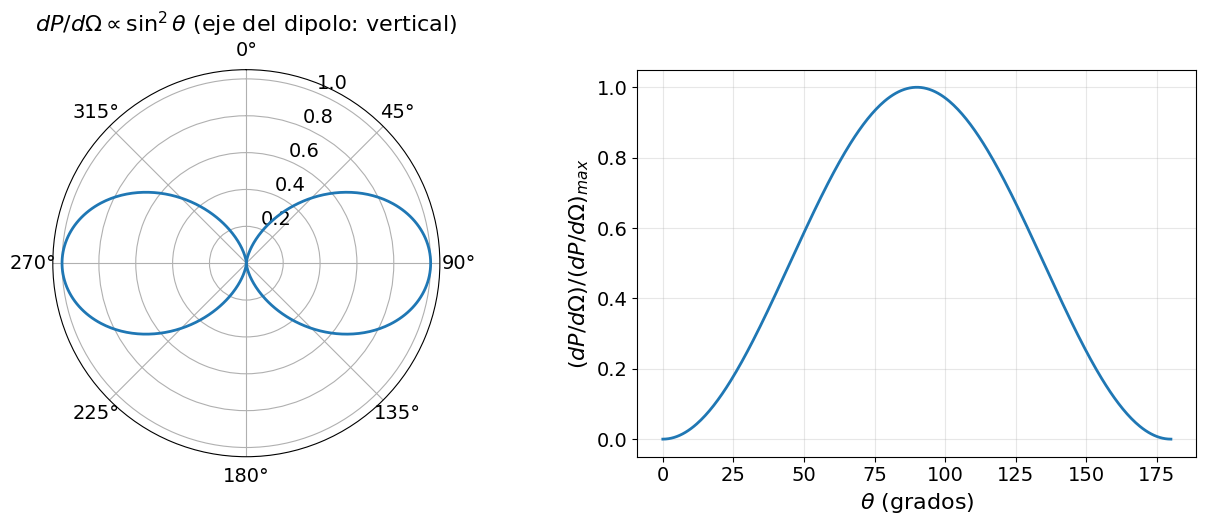

Valores relativos de dP/dΩ (normalizados a θ=90°):
  θ=  0°: dP/dΩ relativo = 0.0000  (sin²θ = 0.0000)
  θ= 30°: dP/dΩ relativo = 0.2500  (sin²θ = 0.2500)
  θ= 45°: dP/dΩ relativo = 0.5000  (sin²θ = 0.5000)
  θ= 60°: dP/dΩ relativo = 0.7500  (sin²θ = 0.7500)
  θ= 90°: dP/dΩ relativo = 1.0000  (sin²θ = 1.0000)


In [18]:
# Fig. 6 — Aspecto 5 / 4.2: patrón angular
patron_angular(angulos=(0, 30, 45, 60, 90), guardar='figuras/fig6_patron_angular.png')